# 🚀 Модуль 5. Урок 2. Теория вероятностей, теорема Байеса и Закон больших чисел

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_05_statistics/lesson_02_probability_bayes_law_of_large_numbers.ipynb)

## 📌 Бизнес-контекст и методология
Принятие решений на малых выборках — одна из главных причин потери бюджетов в маркетинге и продукте. Закон больших чисел объясняет, почему нельзя доверять конверсии лендинга после 50 посетителей. А теорема Байеса объясняет парадокс ложноположительных срабатываний систем антифрода.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Рассчитаем вероятность оттока (`is_churned`) и условную вероятность оттока по тарифам.

In [2]:
df_saas = pd.read_csv(saas_csv)

total_users = len(df_saas)
churned_users = len(df_saas[df_saas['is_churned'] == 1])
p_churn = churned_users / total_users

# P(Churn | Starter plan)
starter_users = df_saas[df_saas['plan'] == 'Starter']
p_churn_given_starter = len(starter_users[starter_users['is_churned'] == 1]) / len(starter_users)

print(f"Общая вероятность оттока P(Churn): {p_churn:.2%}")
print(f"Условная вероятность оттока P(Churn | Starter): {p_churn_given_starter:.2%}")

Общая вероятность оттока P(Churn): 16.80%
Условная вероятность оттока P(Churn | Starter): 21.07%


### 🎬 Анимация: Закон больших чисел в действии (Стабилизация CTR)
**Кейс:** Маркетолог запустил баннер. После первых 40 показов CTR составил 5.0% (2 клика). Маркетолог просит $50,000 на масштабную кампанию.
Запустите интерактивную анимацию ниже: смотрите, как накопленный CTR неистово колеблется на малых n и стабилизируется строго к истинным 2.5% лишь к 1,500 показам!

In [3]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import numpy as np

np.random.seed(42)
true_ctr = 0.025
total_trials = 2000
clicks = np.random.binomial(1, true_ctr, total_trials)
cumulative_ctr = np.cumsum(clicks) / np.arange(1, total_trials + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.set_xlim(1, total_trials)
ax.set_ylim(0, 0.08)
ax.axhline(true_ctr, color='#cc4b37', linestyle='--', linewidth=2, label=f'Истинный CTR = {true_ctr:.1%}')
ax.axvspan(0, 100, alpha=0.15, color='#ffae00', label='Зона ранней паники (n < 100)')
line, = ax.plot([], [], color='#1779ba', linewidth=1.8, label='Накопленный CTR')
ax.set_title('Закон больших чисел: Стабилизация оценки конверсии', fontsize=12, fontweight='bold')
ax.set_xlabel('Количество показов (n)')
ax.set_ylabel('Оценка CTR')
ax.legend(loc='upper right')
ax.grid(True, linestyle=':', alpha=0.6)

frames_list = list(range(10, 200, 10)) + list(range(200, total_trials, 50))

def update(frame):
    x = np.arange(1, frame + 1)
    y = cumulative_ctr[:frame]
    line.set_data(x, y)
    return line,

anim = animation.FuncAnimation(fig, update, frames=frames_list, blit=True)
plt.close(fig)

HTML(anim.to_jshtml())

### 📊 Теорема Байеса: Почему точный антифрод ошибается на 90%
**Кейс:** Система выявления мошеннических транзакций имеет точность 99% (Sensitivity = 0.99, Specificity = 0.99).
Если уровень фрода в базе 0.1% (1 из 1000), какова вероятность того, что помеченная транзакция действительно фрод?
График ниже показывает, как апостериорная вероятность ($P(Fraud | Alert)$) зависит от базовой распространенности фрода.

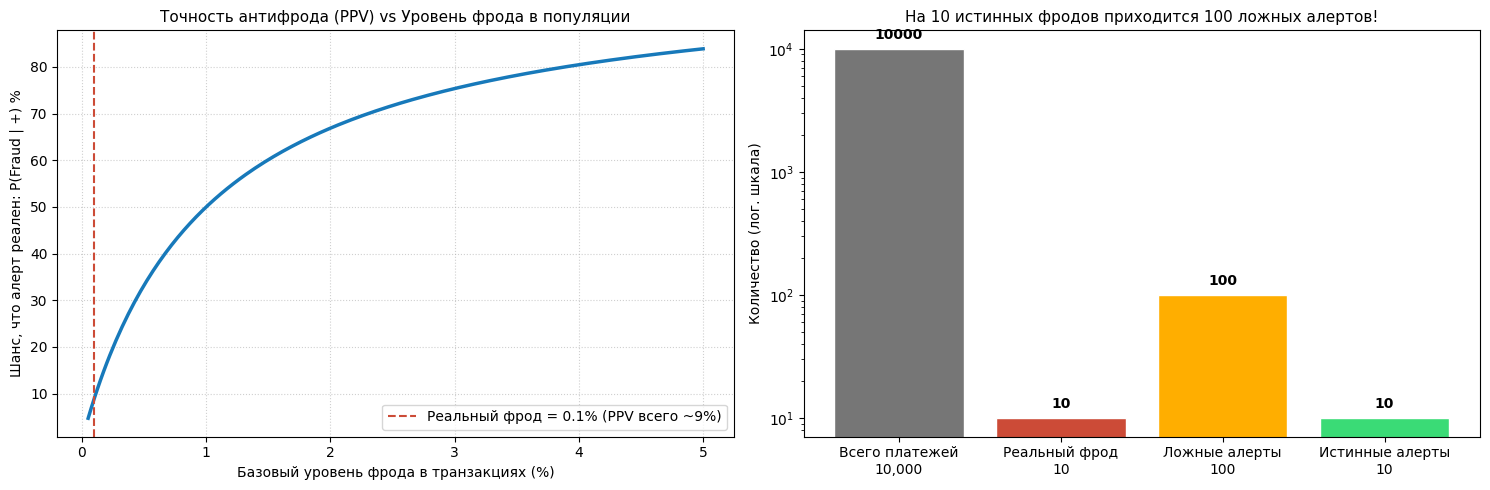

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Зависимость PPV от базового уровня фрода
ax1 = axes[0]
base_rates = np.linspace(0.0005, 0.05, 200)
sensitivity = 0.99
specificity = 0.99

ppv = (sensitivity * base_rates) / (sensitivity * base_rates + (1 - specificity) * (1 - base_rates))
ax1.plot(base_rates * 100, ppv * 100, color='#1779ba', linewidth=2.5)
ax1.set_title('Точность антифрода (PPV) vs Уровень фрода в популяции', fontsize=11)
ax1.set_xlabel('Базовый уровень фрода в транзакциях (%)')
ax1.set_ylabel('Шанс, что алерт реален: P(Fraud | +) %')
ax1.axvline(0.1, color='#cc4b37', linestyle='--', label='Реальный фрод = 0.1% (PPV всего ~9%)')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# 2. Воронка транзакций на 10,000 платежей
ax2 = axes[1]
categories = ['Всего платежей\n10,000', 'Реальный фрод\n10', 'Ложные алерты\n100', 'Истинные алерты\n10']
counts = [10000, 10, 100, 10]
colors = ['#767676', '#cc4b37', '#ffae00', '#3adb76']
bars = ax2.bar(categories, counts, color=colors, edgecolor='white')
ax2.set_yscale('log')
ax2.set_title('На 10 истинных фродов приходится 100 ложных алертов!', fontsize=11)
ax2.set_ylabel('Количество (лог. шкала)')
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval * 1.2, f'{int(yval)}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет вероятности оттока для тарифа Enterprise
Рассчитайте вероятность $P(Churn | Enterprise)$ и убедитесь, что она меньше, чем по тарифу Starter.

In [5]:
### ВАШ КОД ЗДЕСЬ
ent_users = df_saas[df_saas['plan'] == 'Enterprise']
p_churn_enterprise = len(ent_users[ent_users['is_churned'] == 1]) / len(ent_users)

print(f"P(Churn | Enterprise): {p_churn_enterprise:.2%}")
assert p_churn_enterprise < p_churn_given_starter, "Отток в Enterprise должен быть ниже Starter"
print("✅ Тест успешно пройден!")

P(Churn | Enterprise): 4.25%
✅ Тест успешно пройден!


### 💼 Главный вывод для аналитика
При редких событиях (фрод, клики с низким CTR, конверсия в покупку квартиры) даже тест с 99% точностью порождает больше шума, чем сигнала. Всегда калибруйте пороги моделей с учетом базовой вероятности.